We need the classic imports for this sort of work first:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

Now, let's read the data! You can change which light data is being read by changing the `data_dirs` index that's assigned to `selected_dir` (0 is Hydrogen, 1 is Mystery 215, 2 is Mystery 241, 3 is the small light, and 4 is the tube light).

In [2]:
wavelength = []
brightnesses = []
noises = []

data_dirs = ["H", "m215", "m241", "smalllight", "tube", "sunlight"]

# change this line depending on the values to view!
selected_dir = data_dirs[0] 

data_file = 0 # data file count for mean brightness calculation
noise_file = 0 # noise file count for mean brightness calculation

# data files
with open(selected_dir + "/data/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        brightnesses.append([])
        with open(selected_dir + "/data/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                brightnesses[data_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)
        
        data_file += 1

# noise files
if selected_dir != "sunlight":
    with open(selected_dir + "/noise/files.txt") as selected_data:
        files = selected_data.readlines()
        for filename in files:
            i = 0 # metadata skipper
            noises.append([])
            with open(selected_dir + "/noise/" + filename.strip()) as f:
                for line in f: 
                    if i < 13:
                        i += 1
                        continue # skip reading metadata lines
                    (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                    noises[noise_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

            noise_file += 1

wavelength_array = np.array([i for i in range(350, 1001)])
brightness_array = np.array(brightnesses)

mean_brightness = np.mean(brightness_array, axis=0)
mean_brightness_err = np.std(brightness_array, axis=0)

mean_calibrated = mean_brightness
mean_calibrated_err = mean_brightness_err

if selected_dir != "sunlight":
    noise_array = np.array(noises)
    mean_noise = np.mean(noise_array, axis=0)
    mean_noise_err = np.std(noise_array, axis=0)

    mean_calibrated = mean_brightness - mean_noise
    mean_calibrated_err = np.sqrt(mean_brightness_err ** 2 + mean_noise_err ** 2) # error propagation

Awesome! Now we can plot our data:

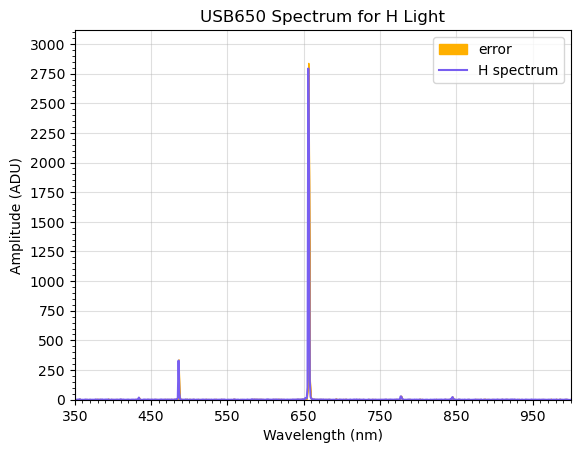

In [3]:
fig, ax = plt.subplots(1)

ax.set_ylim(0, np.max(brightness_array)*1.1)
ax.set_xlim(350, 1000)

ax.set_yticks(np.arange(0, np.max(brightness_array)*1.1, 250))
ax.set_yticks(np.arange(0, np.max(brightness_array)*1.1, 50), minor=True)

ax.set_xticks(np.arange(350, 1000, 100))
ax.set_xticks(np.arange(350, 1005, 10), minor=True)

ax.grid(visible=True, alpha=0.4)

ax.set_ylabel("Amplitude (ADU)")
ax.set_xlabel("Wavelength (nm)")
ax.set_title("USB650 Spectrum for " + selected_dir.capitalize() + " Light")

ax.fill_between(wavelength_array, 
                mean_calibrated - 2*mean_calibrated_err, 
                mean_calibrated + 2*mean_calibrated_err, color='#FFB000', label="error")
ax.plot(wavelength_array, mean_calibrated, color='#785EF0', label=f"{selected_dir} spectrum")

ax.legend()

The graph above uses $2\sigma$ as the error plot, both so that it is visible in (most) plots and represent the overwhelming majority (96%) of the data distribution.
You might also notice some noise in the 500-700nm range for the mystery gases. The distribution of the noise looks quite similar to the tube light distribution, so we suggest that the noise came from other groups who had the tube light on while we made these measurements. Note that this might also have affected the tube light data itself.

Now, we'll use our **Hydrogen measurements** (which have very clear peaks) to determine the calibration of our spectrometer. this will allow us to apply a systematic shift to the data, as we will know by how much the data is offset by calibration. Do note that any calculations onward are only applicable for the Hydrogen light data. 

We'll estimate the peak locations and values using a local Gaussian distribution and `scipy.optimize.curve_fit` to find the estimated parameters to plot this distribution! The helpers are in the next cell (`neat_print` just prints the results out nicely). We assume that no constant offset is needed for our Gaussian distribution since random noise is cancelled out by subtracting ambient frame values from our measurements. We also use an amplifier power, as we do not use any initial guesses for `scipy.optimize.curve_fit`, which means all parameters are guessed around 1 from the start (and using a power of the amplifier makes the original amplifier value closer to 1, hence easier to get to; the 4th power makes all amplifier values less than 10).

In [4]:
def gauss(x_arr, amp, mu, sd):
    """
    Return Gaussian distribution of x_arr with mean mu, standard 
    deviation sd, and amplifier amp.
    """
    return (amp**4) * (np.exp(-0.5 * ((x_arr - mu)/sd)**2)/(sd * (2*np.pi)**0.5))

def est_fit(func, data, data_range, p0):
    """
    Return tuple of best-fit parameters and covariance of data over data_range using func.
    """
    if func == gauss:
        return scp.optimize.curve_fit(func, 
                                      data_range, 
                                      data, 
                                      bounds=([0, min(data_range), 0], 
                                              [10, max(data_range) - 1, 10]),
                                      maxfev=500000
                                     )
    elif func == pois:
        return scp.optimize.curve_fit(func, 
                                      data_range, 
                                      data, 
                                      bounds=([0, min(data_range), 0], 
                                              [10, max(data_range) - 1, 1000]),
                                      p0=p0,
                                      maxfev=500000
                                     )

def neat_print(fit):
    """
    Print fit parameters obtained with est_fit neatly.
    """
    print("Amp: " + str(round(fit[0], 4)) + 
      "\n Mu: " + str(round(fit[1] + 350, 4)) + 
      "\tnm\n SD: " + str(round(fit[2], 4)) + "\tnm\n")

Now, let's estimate our peaks! We expect peaks around 410.17, 434.05, 486.13, and 656.27 nm, so we'll take 20 indices around them from our data to estimate where our measured peaks are:

In [5]:
ranges = (np.array([50, 74, 126, 296]), np.array([71, 95, 147, 317]))
expected = np.array([410.17, 434.05, 486.13, 656.27])

params = [] 
covs = []

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    (fit, cov_matrix) = est_fit(gauss, peak, index, [])
    
    
    print(f"PEAK {str(i+1)} (expected: {expected[i]} nm)")
    neat_print(fit)
    
    params.append(fit)
    covs.append(cov_matrix)
    
print(f'Covariance matrix for PEAK 1: \n{covs[0]}\n' +
      f'These values are exceptionally high (others are in 10^-2 to 10^-8 range) \n' +
      f'    -> Perhaps is it more interesting to try another distribution, such as Poisson?')

PEAK 1 (expected: 410.17 nm)
Amp: 1.907
 Mu: 410.463	nm
 SD: 0.254	nm

PEAK 2 (expected: 434.05 nm)
Amp: 2.2707
 Mu: 433.9933	nm
 SD: 0.5814	nm

PEAK 3 (expected: 486.13 nm)
Amp: 4.4702
 Mu: 486.1463	nm
 SD: 0.4589	nm

PEAK 4 (expected: 656.27 nm)
Amp: 8.3484
 Mu: 656.3819	nm
 SD: 0.5428	nm

Covariance matrix for PEAK 1: 
[[ 6.41363195e+08  3.48375876e+07 -1.19648211e+08]
 [ 3.48375876e+07  1.89230926e+06 -6.49905554e+06]
 [-1.19648211e+08 -6.49905554e+06  2.23207294e+07]]
These values are exceptionally high (others are in 10^-2 to 10^-8 range) 
    -> Perhaps is it more interesting to try another distribution, such as Poisson?


In [6]:
def pois(x_arr, amp, mu, offset):
    """
    Return Poisson distribution using integer array x_arr and mean mu, applying a horizontal offset and amplifier.
    """
    result = (amp**2) * (np.exp(-mu, dtype=np.float128) \
                            * np.power(mu, (x_arr - offset), dtype=np.float128))
    
    # division by factorial, implemented by integer 
    for i in range(0, len(result) - 1):
        for j in range(1, int(x_arr[i] - offset) + 1):
            result[i] /= j
    return result

# the mean is suggested to be the index right after the peak because of the skewed aspect of the Poisson distribution
# for peak 0, this is estimated to be 411nm, i.e. index 61

peak = mean_calibrated[ranges[0][0]:ranges[1][0]]
index = np.arange(ranges[0][0], ranges[1][0], 1)

temp_index = index - 59

params[0], covs[0] = est_fit(pois, peak, temp_index, p0=[10, 1, 59])

print(peak)

print(f'Estimations:\n{params[0]}\n\n Covariance Matrix:\n{covs[0]}\n')

print("Not that much better, especially since that doesn't plot well at all - the parameters don't make any sense!\n")

[ 0.024  0.522  0.03   0.41   0.87   0.332  0.984 -1.148  0.526 -0.252
  3.942  2.222 -0.436  1.416  0.596  0.412 -0.316 -0.13  -0.158  0.558
  1.782]
Estimations:
[  8.03045336   1.02324033 161.83016238]

 Covariance Matrix:
[[ 2.09989538e+03  3.36439254e+00 -1.93709805e+02]
 [ 3.36439254e+00  5.39768915e-03 -3.10356330e-01]
 [-1.93709805e+02 -3.10356330e-01  1.78692182e+01]]

Not that much better, especially since that doesn't plot well at all - the parameters don't make any sense!



Let's try to look at the points themselves on all plots to see what could be going wrong.

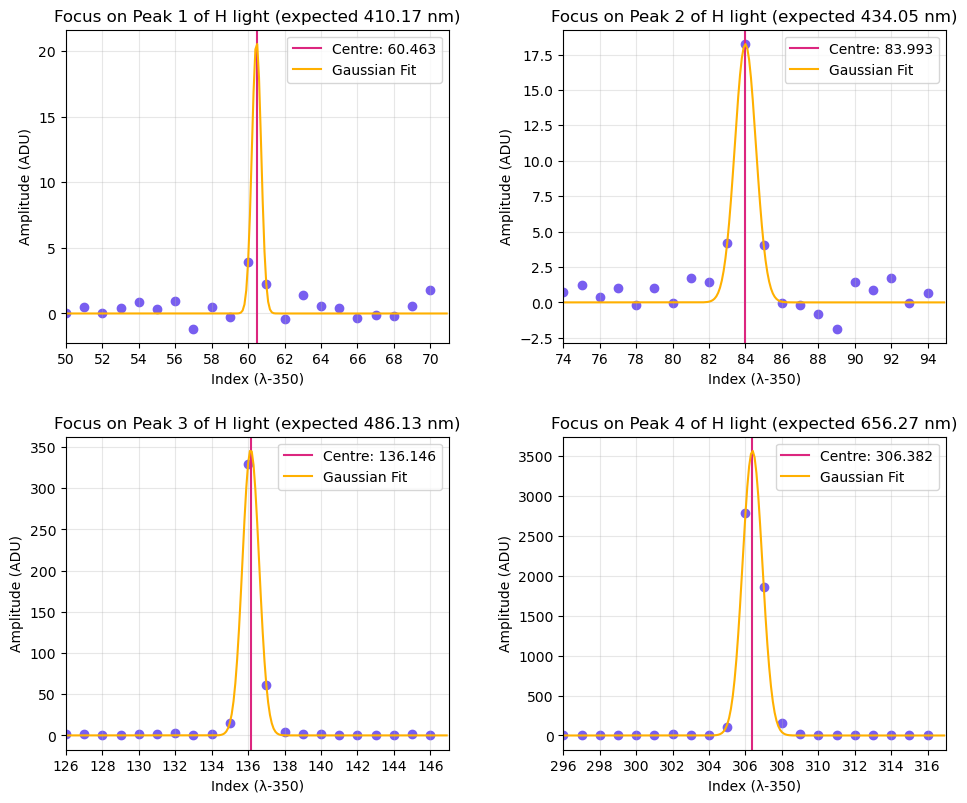

In [7]:
# refit Gaussian over peak 0
peak = mean_calibrated[ranges[0][0]:ranges[1][0]]
index = np.arange(ranges[0][0], ranges[1][0], 1)
    
(params[0], covs[0]) = est_fit(gauss, peak, index, [])

# end of refitting

fig, axs = plt.subplots(2, 2)
plt.subplots_adjust(bottom=0, right=1.5, top=1.5, wspace=0.3, hspace=0.3)

peak_indices = []
peak_mags = []

axs[0][0].set_xlim(50, 71)
axs[0][1].set_xlim(74, 95)
axs[1][0].set_xlim(126, 147)
axs[1][1].set_xlim(296, 317)

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    axs[i//2][i%2].scatter(index, peak, color="#785EF0")
    
    amp = params[i][0]
    mu = params[i][1]
    sd = params[i][2]
    
    axs[i//2][i%2].axvline(mu, color="#DC267F", label=f"Centre: {round(mu, 3)}")

    axs[i//2][i%2].set_xticks([i for i in index if i%2 == 0])
    axs[i//2][i%2].grid(alpha=0.3)

    axs[i//2][i%2].set_title(f"Focus on Peak {i+1} of H light (expected {expected[i]} nm)")
    axs[i//2][i%2].set_xlabel("Index (λ-350)")
    axs[i//2][i%2].set_ylabel("Amplitude (ADU)")
    
    overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
    axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color='#FFB000', label='Gaussian Fit')

    axs[i//2][i%2].legend()

    peak_indices.append(mu)
    peak_mags.append(gauss(mu, amp, mu, sd))

Most of the points in the last 3 peaks seem to clearly show some sort of Gaussian, but that's not the case with peak 0. The culprits might be the points at indices 59 and 61, that drop much more harshly compared to their neighbours. Perhaps we could get a better Gaussian fit if we omitted these points.

In [8]:
peak0 = mean_calibrated[50:57]
peak1 = mean_calibrated[58:59]
peak2 = mean_calibrated[60:62]
peak3 = mean_calibrated[64:71]

peak = np.concatenate((peak0, peak1, peak2, peak3))

print(peak)

index0 = np.arange(50, 57, 1)
index1 = np.arange(58, 59, 1)
index2 = np.arange(60, 62, 1)
index3 = np.arange(64, 71, 1)

index = np.concatenate((index0, index1, index2, index3))

print(index)
    
params[0], covs[0] = est_fit(gauss, peak, index, [1.65, 60.2, 0.7])
    
    
print(f"PEAK 0 (expected: {expected[0]} nm)")
neat_print(params[0])

params.append(fit)
covs.append(cov_matrix)
    
print(f'Covariance matrix for PEAK 1: \n{covs[0]}\n')

[ 0.024  0.522  0.03   0.41   0.87   0.332  0.984  0.526  3.942  2.222
  0.596  0.412 -0.316 -0.13  -0.158  0.558  1.782]
[50 51 52 53 54 55 56 58 60 61 64 65 66 67 68 69 70]
PEAK 0 (expected: 410.17 nm)
Amp: 1.7631
 Mu: 409.9542	nm
 SD: 0.9774	nm

Covariance matrix for PEAK 1: 
[[ 0.01193328 -0.01649923  0.01879368]
 [-0.01649923  0.08838171 -0.01994043]
 [ 0.01879368 -0.01994043  0.05435875]]



This is a much stronger fit, implying that the data had some "outlier" values. This issue is also certainly linked to the fact that the signal-to-noise ratio (S/N) becoming particularly low, as the points near the peak reach between 2-4 ADUs while non-peak (= noise) values are usually in the -2 to 1 ADU.<br>
The peak we find is also particularly far from the expected peak wavelength relative to otehr peaks, which is likely also because of the S/N ratio.

Now, we can overplot our distributions over the index ranges of our peaks and estimate the peak brightness:

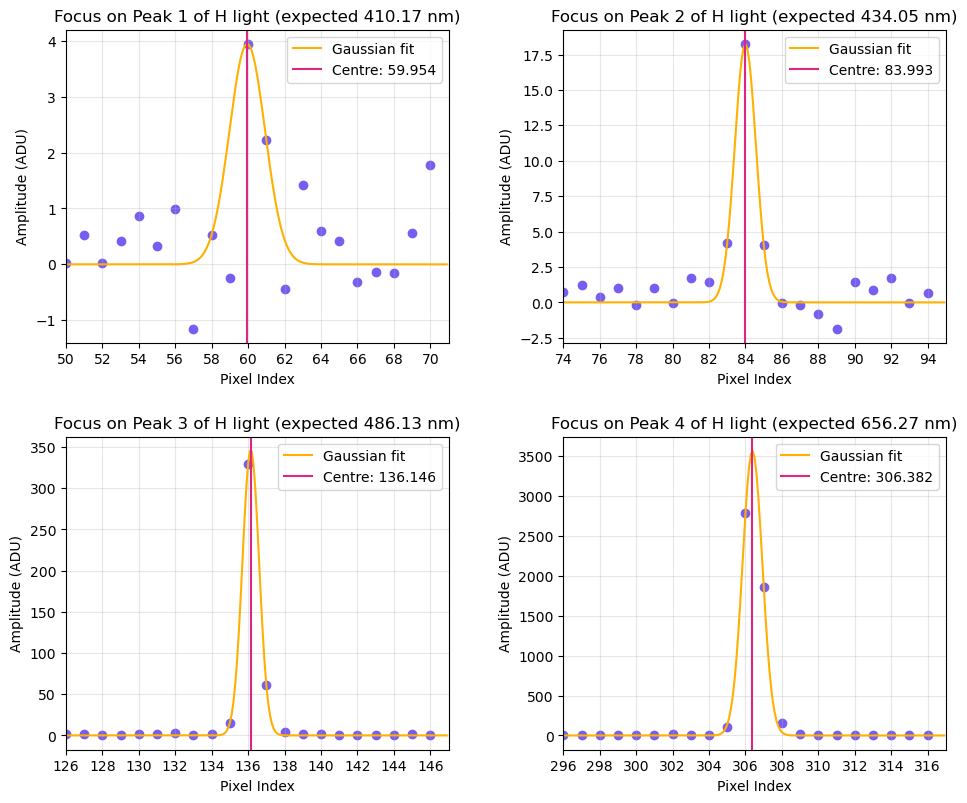

In [9]:
fig, axs = plt.subplots(2, 2)
plt.subplots_adjust(bottom=0, right=1.5, top=1.5, wspace=0.3, hspace=0.3)

peak_indices = []
peak_mags = []

axs[0][0].set_xlim(50, 71)
axs[0][1].set_xlim(74, 95)
axs[1][0].set_xlim(126, 147)
axs[1][1].set_xlim(296, 317)

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    axs[i//2][i%2].scatter(index, peak, color="#785EF0")
    
    amp = params[i][0]
    mu = params[i][1]
    
    """
    if i == 0: # special Poisson overplot for the first peak
        overplot_range = np.arange(ranges[0][i], ranges[1][i], 1) # pois only supports integer x_arr values

        offset = params[i][2]
        
        print(pois(overplot_range, amp, mu, offset))
        
        axs[i//2][i%2].plot(overplot_range, pois(overplot_range, amp, mu, offset), color="#FFB000", label="Poisson fit")
        
    else:

        overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
        
        sd = params[i][2]
        axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color="#FFB000", label="Gaussian fit")
    """
    overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
        
    sd = params[i][2]
    axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color="#FFB000", label="Gaussian fit")
    axs[i//2][i%2].axvline(mu, color="#DC267F", label=f"Centre: {round(mu, 3)}")

    axs[i//2][i%2].set_xticks([i for i in index if i%2 == 0])
    axs[i//2][i%2].grid(alpha=0.3)

    axs[i//2][i%2].set_title(f"Focus on Peak {i+1} of H light (expected {expected[i]} nm)")
    axs[i//2][i%2].set_xlabel("Pixel Index")
    axs[i//2][i%2].set_ylabel("Amplitude (ADU)")

    axs[i//2][i%2].legend()

    peak_indices.append(mu)
    peak_mags.append(gauss(mu, amp, mu, sd))

We need to reshift our index values to wavelength values in nm, and can plot our peak wavelength and estimated magnitude!

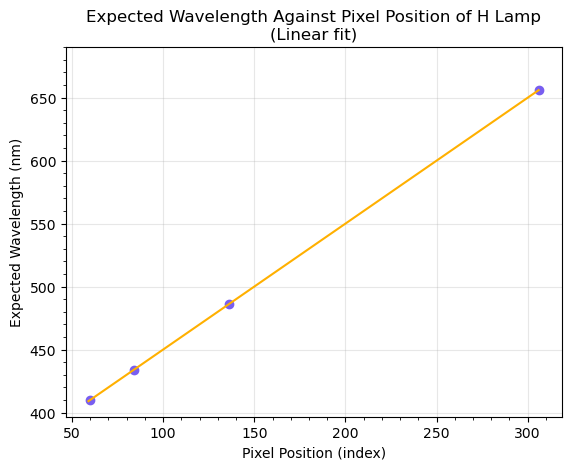

Residuals: [ 0.1345 -0.0824 -0.0871  0.035 ]


In [10]:
def least_squares(x_arr, y_arr, N):
    """
    Return a tuple of gradient (m) and constant (c) for linear regression using values from arrays x_arr and y_arr.
    Both arrays contain N entries.
    """    
    x_arr2 = x_arr ** 2
    xy_arr = x_arr * y_arr
    
    sum_x = np.sum(x_arr)
    sum_y = np.sum(y_arr)
    sum_x2 = np.sum(x_arr2)
    sum_xy = np.sum(xy_arr)
    
    det = (N * sum_x2 - sum_x ** 2)**(-1)

    m = det * (sum_xy * N - sum_y * sum_x)
    c = det * (sum_y * sum_x2 - sum_xy * sum_x)

    return (m, c)

def lin_residuals(x_arr, y_arr, m, c):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using linear regression with slope m and y-intercept c.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (m * x_arr[i] + c))
    
    return np.array(residuals)

##########
# PLOTTING
##########
peak_indices = np.array(peak_indices)
H_lines = np.array([410.2, 434.0, 486.1, 656.3])

# perform least squares linear regression on the data and calculate residuals
(m, c) = least_squares(peak_indices, H_lines, 4)
lin_residuals0 = lin_residuals(peak_indices, H_lines, m, c)

lin_range = np.arange(int(peak_indices[0]), int(peak_indices[-1] + 1), 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_indices, H_lines, color="#785EF0")
ax.plot(lin_range, m * lin_range + c, color="#FFB000", label="Linear")

ax.set_title("Expected Wavelength Against Pixel Position of H Lamp\n(Linear fit)")

ax.set_ylabel("Expected Wavelength (nm)")
ax.set_xlabel("Pixel Position (index)")

ax.set_xticks(np.arange(50, 320, 10), minor=True)
ax.set_yticks(np.arange(400, 700, 10), minor=True)

ax.grid(visible=True, alpha=0.3)
plt.show()

print(f"Residuals: {np.round(lin_residuals0, 4)}")

It is also useful to try to replot this graph omitting peak 0 because of its inconsistency, to check for any significant changes in the fit.

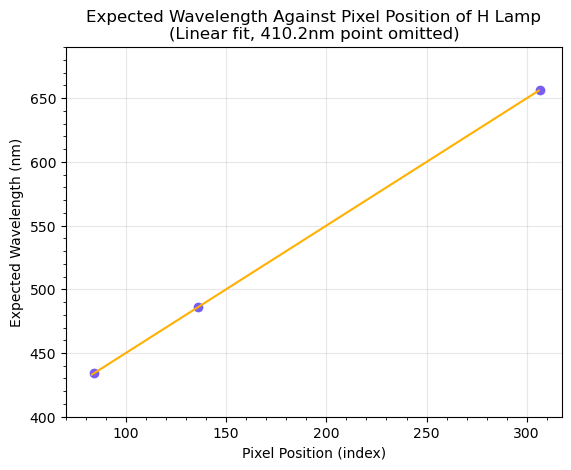

Residuals: [ 0.015  -0.0196  0.0046]


In [11]:
def lin_residuals(x_arr, y_arr, m, c):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using linear regression with slope m and y-intercept c.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (m * x_arr[i] + c))
    
    return np.array(residuals)

# perform least squares linear regression on the data and calculate residuals
(m1, c1) = least_squares(peak_indices[1:], H_lines[1:], 3)
lin_residuals1 = lin_residuals(peak_indices[1:], H_lines[1:], m1, c1)

lin_range = np.arange(int(peak_indices[1]), int(peak_indices[-1] + 1), 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_indices[1:], H_lines[1:], color="#785EF0")
ax.plot(lin_range, m * lin_range + c, color="#FFB000", label="Linear")

ax.set_title("Expected Wavelength Against Pixel Position of H Lamp\n(Linear fit, 410.2nm point omitted)")

ax.set_ylabel("Expected Wavelength (nm)")
ax.set_xlabel("Pixel Position (index)")

ax.set_xticks(np.arange(70, 320, 10), minor=True)
ax.set_yticks(np.arange(400, 700, 10), minor=True)

ax.grid(visible=True, alpha=0.3)
plt.show()

print(f"Residuals: {np.round(lin_residuals1, 4)}")

The residuals show significantly lower values when omitting the first point and the residual value for it in the first graph is 2 orders of magnitude larger than other points, strongly suggesting that the data collected does not allow appropriate use of this point.<br>
This could have been solved by using a higher integration time, as that would have increased the magnitude of the peak and rendered our fits and estimations stronger, but we must also keep in mind that this would affect the magnitude of other peaks, which could reach saturation.<br><br>
We will now repeat these graphs using quadratic regression, in order to assess whether this different regression type would allow for a better fit with lower residuals. We will do this using `scipy.optimize.curve_fit` once again.

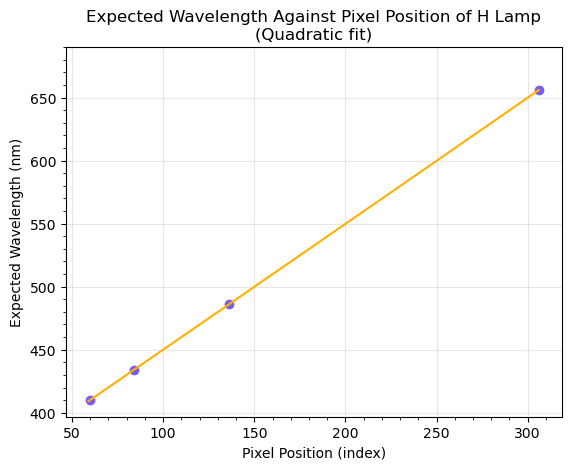

Residuals: [ 0.0512 -0.0828  0.0341 -0.0025]


In [12]:
def quad(x_arr, a, b, c):
    """
    Return ax^2 + bx + c, quadratic values of x_arr with parameters a, b, c.
    """
    return a * (x_arr ** 2) + b * x_arr + c

def quad_residuals(x_arr, y_arr, a, b, c):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using quadratic regression of the form ax^2 + bx + c.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (a * (x_arr[i]**2) + b * x_arr[i] + c))
    
    return np.array(residuals)

##########
# PLOTTING
##########
(quad_fit, quad_cov) = np.polyfit(peak_indices, H_lines, 2, cov=True)

quad_residuals0 = quad_residuals(peak_indices, H_lines, quad_fit[0], quad_fit[1], quad_fit[2])

lin_range = np.arange(int(peak_indices[0]), int(peak_indices[-1] + 1), 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_indices, H_lines, color="#785EF0")
ax.plot(lin_range, quad_fit[0] * lin_range**2 + quad_fit[1] * lin_range + quad_fit[2], color="#FFB000", label="Quadratic")

ax.set_title("Expected Wavelength Against Pixel Position of H Lamp\n(Quadratic fit)")

ax.set_ylabel("Expected Wavelength (nm)")
ax.set_xlabel("Pixel Position (index)")

ax.set_xticks(np.arange(50, 320, 10), minor=True)
ax.set_yticks(np.arange(400, 700, 10), minor=True)

ax.grid(visible=True, alpha=0.3)
plt.show()

print(f"Residuals: {np.round(quad_residuals0, 4)}")

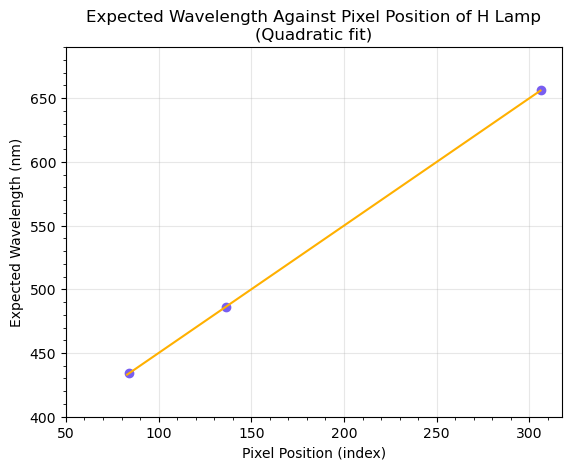

Residuals: [0. 0. 0.]


In [13]:
quad_fit1 = np.polyfit(peak_indices[1:], H_lines[1:], 2)

quad_residuals1 = quad_residuals(peak_indices[1:], H_lines[1:], quad_fit1[0], quad_fit1[1], quad_fit1[2])

lin_range = np.arange(int(peak_indices[1]), int(peak_indices[-1] + 1), 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_indices[1:], H_lines[1:], color="#785EF0")
ax.plot(lin_range, quad_fit1[0] * lin_range**2 + quad_fit1[1] * lin_range + quad_fit1[2], color="#FFB000", label="Quadratic (3-point)")

ax.set_title("Expected Wavelength Against Pixel Position of H Lamp\n(Quadratic fit)")

ax.set_ylabel("Expected Wavelength (nm)")
ax.set_xlabel("Pixel Position (index)")

ax.set_xticks(np.arange(50, 320, 10), minor=True)
ax.set_yticks(np.arange(400, 700, 10), minor=True)

ax.grid(visible=True, alpha=0.3)
plt.show()

print(f"Residuals: {np.round(quad_residuals1, 4)}")

The residuals are significantly smaller, as expected: the more parameters, the lower the residuals get, until they all equal zero when the polynomial order equals the number of points.
We will not inspect the quadratic fitting over 3 points, as there are infinite quadratic fits passing through them.<br><br>
We can also compare the residuals side by side for the linear and quadratic fitting!

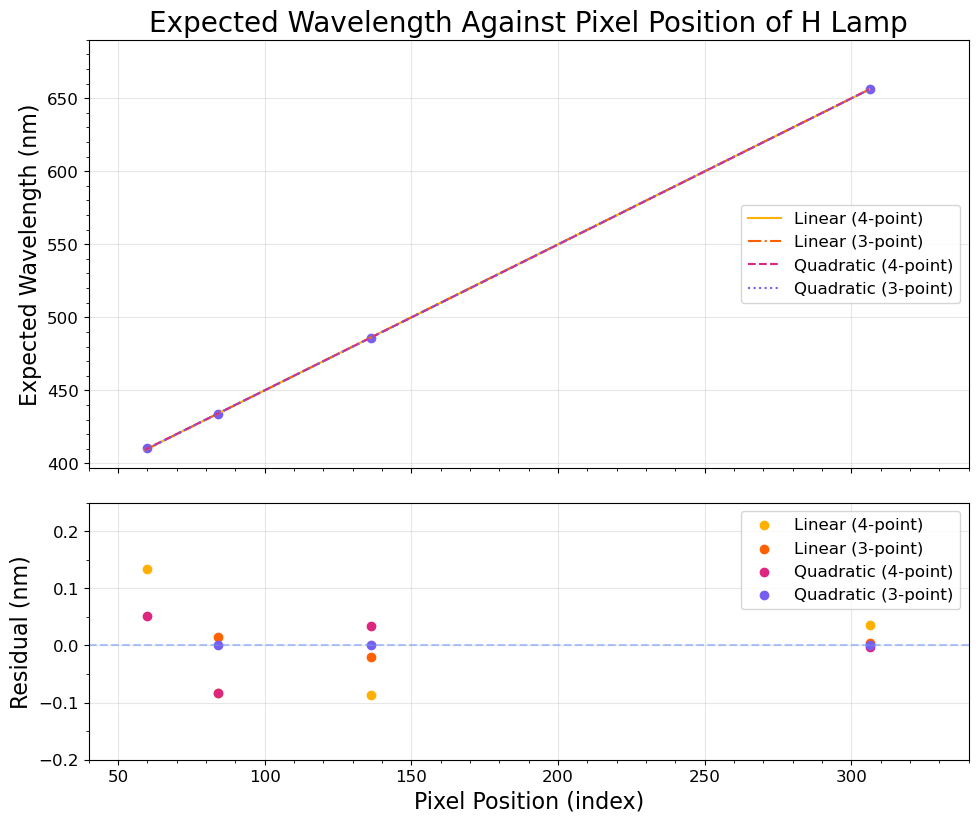

Absolute sum of residuals per fit:
Linear 4-point:	0.33894834023215026
Linear 3-point:	0.03924064130740135
Quadratic:	0.17058054463029748

We are selecting the linear 3-point fit because it is the one with the lowest residuals.
Thus, our calibration parameters are:
m = 0.9996, c = 350.0211


In [14]:
lin_range = np.arange(int(peak_indices[0]), int(peak_indices[-1] + 1), 1)

fig, axs = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [5, 3], 'bottom': 0, 
                                                        'right': 1.5, 'top': 1.5, 'wspace': 0.3, 'hspace': 0.1})
plt.subplots_adjust(bottom=0, right=15, top=3, wspace=0.3, hspace=0.3)

##########
# DATA
##########
axs[0].scatter(peak_indices, H_lines, color="#785EF0")
axs[0].plot(lin_range, m * lin_range + c, color="#FFB000", label="Linear (4-point)", ls="-")
axs[0].plot(lin_range, m1 * lin_range + c1, color="#FE6100", label="Linear (3-point)", ls="dashdot")
axs[0].plot(lin_range, quad_fit[0] * lin_range**2 + quad_fit[1] * lin_range + quad_fit[2], 
            color="#DC267F", label="Quadratic (4-point)", ls="--")
axs[0].plot(lin_range, quad_fit1[0] * lin_range**2 + quad_fit1[1] * lin_range + quad_fit1[2], 
            color="#785EF0", label="Quadratic (3-point)", ls="dotted")

axs[0].set_title("Expected Wavelength Against Pixel Position of H Lamp", fontsize=20)

axs[0].set_ylabel("Expected Wavelength (nm)", fontsize=16)

axs[0].set_yticks(np.arange(400, 700, 10), minor=True)
axs[0].tick_params(labelsize=12)

axs[0].grid(visible=True, alpha=0.3)

##########
# RESIDUALS
##########
axs[1].scatter(peak_indices, lin_residuals0, color="#FFB000", label="Linear (4-point)")
axs[1].scatter(peak_indices[1:], lin_residuals1, color="#FE6100", label="Linear (3-point)")
axs[1].scatter(peak_indices, quad_residuals0, color="#DC267F", label="Quadratic (4-point)")
axs[1].scatter(peak_indices[1:], quad_residuals1, color="#785EF0", label="Quadratic (3-point)")

axs[1].set_yticks(np.arange(-0.2, 0.3, 0.05), minor=True)
axs[1].set_xticks(np.arange(40, 350, 10), minor=True)
axs[1].tick_params(labelsize=12)

axs[1].axhline(0, alpha=0.5, color="#648FFF", ls="dashed")

axs[1].set_xlabel("Pixel Position (index)", fontsize=16)
axs[1].set_ylabel("Residual (nm)", fontsize=16)

axs[1].grid(visible=True, alpha=0.3)

axs[0].legend(loc='center right', fontsize=12)
axs[1].legend(fontsize=12)
plt.show()

print(f"Absolute sum of residuals per fit:\n" +
      f"Linear 4-point:\t{np.sum(np.abs(lin_residuals0))}\n" +
      f"Linear 3-point:\t{np.sum(np.abs(lin_residuals1))}\n" +
      f"Quadratic:\t{np.sum(np.abs(quad_residuals0))}\n"
     )

print(f"We are selecting the linear 3-point fit because it is the one with the lowest residuals.\n" +
      f"Thus, our calibration parameters are:\nm = {np.round(m1, 4)}, c = {np.round(c1, 4)}")

This once again strongly suggests that the first peak is an outlier: we would otherwise suppose that the quadratic fit would yield a lower absolute residual sum than both linear fits, but the linear 3-point fit is nearly 1 order of magnitude lower than the quadratic fit!<br><br>
Thus, we will be using a linear fit for our calibration when looking at the mystery gases, but will keep in mind the quadratic fit once we determine the mystery gases and get more points to fit with.<br><br>
Now, let's get our data for the mystery gases!

In [15]:
wavelength215 = []
brightnesses215 = []
noises215 = []
wavelength241 = []
brightnesses241 = []
noises241 = []

data_dirs = ["H", "m215", "m241", "smalllight", "tube"]

##########
# MYSTERY 215
##########
selected_dir = data_dirs[1]

data_file = 0 # data file count for mean brightness calculation
noise_file = 0 # noise file count for mean brightness calculation

# data files
with open(selected_dir + "/data/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        brightnesses215.append([])
        with open(selected_dir + "/data/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                brightnesses215[data_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

        data_file += 1

# noise files
with open(selected_dir + "/noise/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        noises215.append([])
        with open(selected_dir + "/noise/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                noises215[noise_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

        noise_file += 1

brightness_array215 = np.array(brightnesses215)
noise_array215 = np.array(noises215)

mean_brightness215 = np.mean(brightness_array215, axis=0)
mean_brightness_err215 = np.std(brightness_array215, axis=0)

mean_noise215 = np.mean(noise_array215, axis=0)
mean_noise_err215 = np.std(noise_array215, axis=0)

mean_calibrated215 = mean_brightness215 - mean_noise215
mean_calibrated_err215 = np.sqrt(mean_brightness_err215 ** 2 + mean_noise_err215 ** 2) # error propagation


##########
# MYSTERY 241
##########
selected_dir = data_dirs[2]

data_file = 0 # data file count for mean brightness calculation
noise_file = 0 # noise file count for mean brightness calculation

# data files
with open(selected_dir + "/data/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        brightnesses241.append([])
        with open(selected_dir + "/data/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                brightnesses241[data_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

        data_file += 1

# noise files
with open(selected_dir + "/noise/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        noises241.append([])
        with open(selected_dir + "/noise/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                noises241[noise_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

        noise_file += 1

brightness_array241 = np.array(brightnesses241)
noise_array241 = np.array(noises241)

mean_brightness241 = np.mean(brightness_array241, axis=0)
mean_brightness_err241 = np.std(brightness_array241, axis=0)

mean_noise241 = np.mean(noise_array241, axis=0)
mean_noise_err241 = np.std(noise_array241, axis=0)

mean_calibrated241 = mean_brightness241 - mean_noise241
mean_calibrated_err241 = np.sqrt(mean_brightness_err241 ** 2 + mean_noise_err241 ** 2) # error propagation

index_array = np.arange(0, 651, 1)
wavelength_array = index_array * m1 + c1

Let's plot the data now!

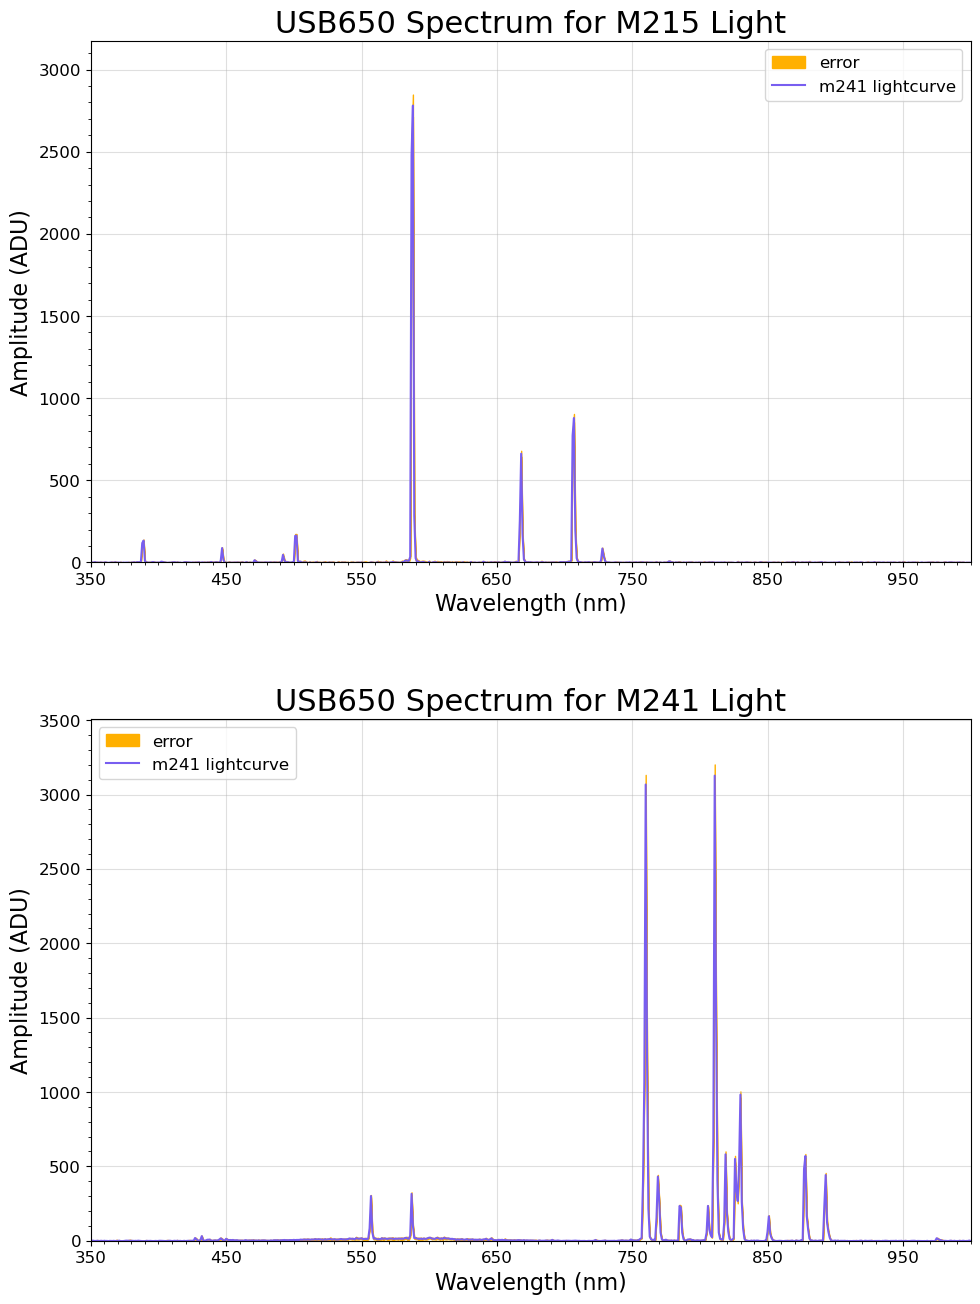

In [16]:
##########
# PLOTTING
##########
fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=2.5, wspace=0.3, hspace=0.3)

##########
# M215
##########
axs[0].set_ylim(0, np.max(brightness_array215)*1.1)
axs[0].set_xlim(350, 1000)

axs[0].set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 500))
axs[0].set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 100), minor=True)

axs[0].set_xticks(np.arange(350, 1000, 100))
axs[0].set_xticks(np.arange(350, 1005, 10), minor=True)

axs[0].tick_params(labelsize=12)
axs[0].grid(visible=True, alpha=0.4)

axs[0].set_ylabel("Amplitude (ADU)", fontsize=16)
axs[0].set_xlabel("Wavelength (nm)", fontsize=16)
axs[0].set_title("USB650 Spectrum for " + data_dirs[1].capitalize() + " Light", fontsize=22)

axs[0].fill_between(wavelength_array, 
                mean_calibrated215 - 2*mean_calibrated_err215, 
                mean_calibrated215 + 2*mean_calibrated_err215, color='#FFB000', label="error")
axs[0].plot(wavelength_array, mean_calibrated215, color='#785EF0', label=f"{selected_dir} lightcurve")

axs[0].legend(fontsize=12)

##########
# M241
##########
axs[1].set_ylim(0, np.max(brightness_array241)*1.1)
axs[1].set_xlim(350, 1000)

axs[1].set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 500))
axs[1].set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 100), minor=True)

axs[1].set_xticks(np.arange(350, 1000, 100))
axs[1].set_xticks(np.arange(350, 1005, 10), minor=True)

axs[1].tick_params(labelsize=12)
axs[1].grid(visible=True, alpha=0.4)

axs[1].set_ylabel("Amplitude (ADU)", fontsize=16)
axs[1].set_xlabel("Wavelength (nm)", fontsize=16)
axs[1].set_title("USB650 Spectrum for " + data_dirs[2].capitalize() + " Light", fontsize=22)

axs[1].fill_between(wavelength_array, 
                mean_calibrated241 - 2*mean_calibrated_err241, 
                mean_calibrated241 + 2*mean_calibrated_err241, color='#FFB000', label="error")
axs[1].plot(wavelength_array, mean_calibrated241, color='#785EF0', label=f"{selected_dir} lightcurve")

axs[1].legend(loc='upper left', fontsize=12)

Let's try to identify the peaks in there! We'll start with Mystery 215. The `m_215` ranges for centroid calculation were estimated by looking at data near the peaks manually, but this could have been done by using `SciPy`'s `find_peaks` as well.

In [17]:
def centroid(x_arr, data):
    """
    return the centroid of data over x_arr. x_arr and data must be the same length
    """
    w_sum = 0
    tot_data = 0
    
    for point in range(len(x_arr)):
        w_sum += x_arr[point] * data[point]
        tot_data += data[point]
    
    centroid = w_sum / tot_data
    return centroid

m215_ranges = ([36, 96, 121, 140, 151, 232, 314, 352, 377], [42, 99, 123, 146, 156, 243, 322, 362, 381])
m215_centroids = []

for i in range(len(m215_ranges[0])):
    m215_centroids.append(m1 * (centroid(np.arange(m215_ranges[0][i], m215_ranges[1][i], 1), 
                              mean_calibrated215[m215_ranges[0][i]:m215_ranges[1][i]])) + c1)
    print(f"CENTROID {i}: \t{round(m215_centroids[i], 3)} nm")

# for plotting
m215c = np.array(m215_centroids)


CENTROID 0: 	388.554 nm
CENTROID 1: 	447.044 nm
CENTROID 2: 	471.332 nm
CENTROID 3: 	492.206 nm
CENTROID 4: 	501.58 nm
CENTROID 5: 	587.521 nm
CENTROID 6: 	667.864 nm
CENTROID 7: 	706.595 nm
CENTROID 8: 	728.211 nm


We can overplot these on the graph above, and check on NIST for which gas this could be.

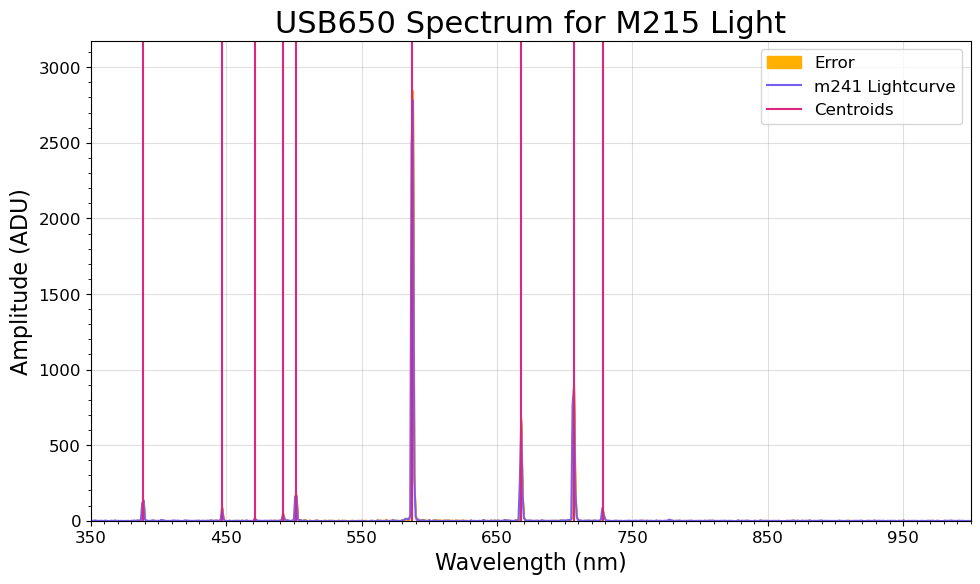

In [18]:
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

ax.set_ylim(0, np.max(brightness_array215)*1.1)
ax.set_xlim(350, 1000)

ax.set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 500))
ax.set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 100), minor=True)

ax.set_xticks(np.arange(350, 1000, 100))
ax.set_xticks(np.arange(350, 1005, 10), minor=True)

ax.tick_params(labelsize=12)
ax.grid(visible=True, alpha=0.4)

ax.set_ylabel("Amplitude (ADU)", fontsize=16)
ax.set_xlabel("Wavelength (nm)", fontsize=16)
ax.set_title("USB650 Spectrum for " + data_dirs[1].capitalize() + " Light", fontsize=22)

ax.fill_between(wavelength_array, 
                mean_calibrated215 - 2*mean_calibrated_err215, 
                mean_calibrated215 + 2*mean_calibrated_err215, color='#FFB000', label="Error")
ax.plot(wavelength_array, mean_calibrated215, color='#785EF0', label=f"{selected_dir} Lightcurve")

for i in range(1, len(m215c)):
    ax.axvline(m215c[i], color="#DC267F")

ax.axvline(m215c[0], color="#DC267F", label="Centroids")
ax.legend(fontsize=12)

From the peaks that we are observing, the most likely gas seems to be Helium I: the significantly largest peak is at 587nm, with other peaks at 706nm, 501nm, 388nm, 728nm, 447nm, 471nm, and 492nm.<br><br>
By elimination, Neon I does not seem to make sense, as we would otherwise get significant peaks in the 350-380nm range and around 600nm, and the 585nm peak seems far from our 587nm one.<br>
Argon I cannot be our gas, as we are missing the many large peaks in the 750-980nm range for the gas, and lacks any of our peaks between 350-750nm. (However, some quick checking might make us claim this is our other gas, Mystery 241!)<br>
We are missing many peak lines for our gas to be Krypton I, such as the 810.4nm and 985.6nm ones, alongside others in the 800-850nm range. The largest peaks in the 430-455nm range also do not fit with our findings.<br>
The same reasoning can be applied to Xenon I, which presents its primary peaks in the 800-990nm range. The less significant peaks (such as 473.4nm and more in the 480-490nm range, as well as 395.1nm and 396.8nm) do not coincide with our findings.<br><br>

We can do the same for the peaks in Mystery 241. We will select values above or near 5 ADUs as our threshold for use in centroid calculations (as opposed to roughly 2 ADUs in Mystery 215, which seems to have less noise). For the peaks in the 550-590nm range, values around 10 ADUs will be considered noise (this is noticeable to the naked eye on the Mystery 241 plot above): 

In [19]:
print(f"{mean_calibrated241[200:250]}\n")
print(f"Notice how almost all values are consistently above 10 ADUs, hence why we consider them noise.")

[ 16.1    11.566  12.148  12.072  11.458  13.692  83.572 300.674  57.778
  13.844  15.332  11.95    9.104  10.744   9.784  16.918  11.806  15.342
  13.594  12.258  13.432  14.54   14.634  14.362  11.534  14.298  13.36
  13.458  14.388  13.298  13.868  13.074  17.37   19.308  14.512  13.026
  33.246 314.912 101.514  17.886  17.596  14.696  12.734  12.822  13.802
  11.526  15.01   12.42   13.34   16.522]

Notice how almost all values are consistently above 10 ADUs, hence why we consider them noise.


In [20]:
m241_ranges = ([77, 81, 85, 93, 98, 206, 236, 405, 417, 435, 454, 459, 466, 473, 478, 500, 525, 542, 625], 
               [80, 84, 89, 99, 102, 209, 239, 417, 423, 439, 460, 468, 474, 479, 484, 505, 532, 547, 629])
m241_centroids = []

for i in range(len(m241_ranges[0])):
    m241_centroids.append(centroid(np.arange(m241_ranges[0][i], m241_ranges[1][i], 1), 
                              mean_calibrated241[m241_ranges[0][i]:m241_ranges[1][i]]))
    print(f"CENTROID {i}: \t{round(m241_centroids[i], 3)} index")

# for plotting
m241c = np.array(m241_centroids)
m241c = m241c * m1 + c1

print(m241c)

CENTROID 0: 	77.454 index
CENTROID 1: 	81.927 index
CENTROID 2: 	86.908 index
CENTROID 3: 	95.849 index
CENTROID 4: 	100.074 index
CENTROID 5: 	206.942 index
CENTROID 6: 	237.152 index
CENTROID 7: 	409.979 index
CENTROID 8: 	419.261 index
CENTROID 9: 	435.692 index
CENTROID 10: 	456.367 index
CENTROID 11: 	461.323 index
CENTROID 12: 	469.211 index
CENTROID 13: 	476.698 index
CENTROID 14: 	479.728 index
CENTROID 15: 	501.125 index
CENTROID 16: 	527.897 index
CENTROID 17: 	543.079 index
CENTROID 18: 	625.933 index
[427.44751224 431.91953839 436.89825975 445.8365155  450.0597691
 556.89010698 587.08966769 759.85664055 769.13481103 785.56060847
 806.22762001 811.18170316 819.06765788 826.55218981 829.58040737
 850.97054834 877.73240335 892.90937427 975.7340866 ]


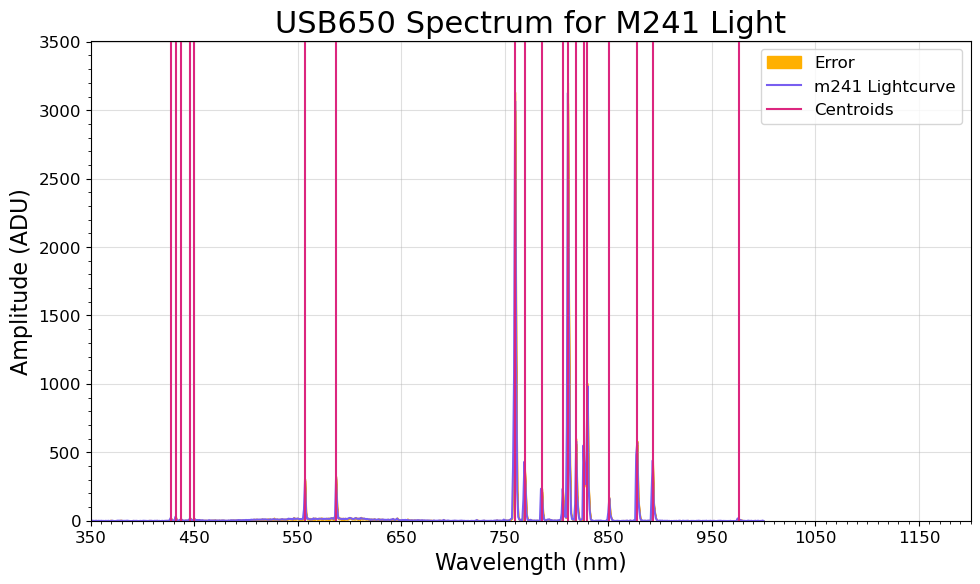

In [21]:
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

ax.set_ylim(0, np.max(brightness_array241)*1.1)
ax.set_xlim(350, 1000)

ax.set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 500))
ax.set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 100), minor=True)

ax.set_xticks(np.arange(350, 1200, 100))
ax.set_xticks(np.arange(350, 1205, 10), minor=True)

ax.tick_params(labelsize=12)
ax.grid(visible=True, alpha=0.4)

ax.set_ylabel("Amplitude (ADU)", fontsize=16)
ax.set_xlabel("Wavelength (nm)", fontsize=16)
ax.set_title("USB650 Spectrum for " + data_dirs[2].capitalize() + " Light", fontsize=22)

ax.fill_between(wavelength_array, 
                mean_calibrated241 - 2*mean_calibrated_err241, 
                mean_calibrated241 + 2*mean_calibrated_err241, color='#FFB000', label="Error")
ax.plot(wavelength_array, mean_calibrated241, color='#785EF0', label=f"{selected_dir} Lightcurve")

for i in range(1, len(m241c)):
    ax.axvline(m241c[i], color="#DC267F")

ax.axvline(m241c[0], color="#DC267F", label="Centroids")
ax.legend(fontsize=12)

We know that Mystery 241 cannot be Helium I if Mystery 215 is, as the spectra are vastly different from each other. This means we are left with checking for similarities with Argon I, Neon I, Krypton I, and Xenon I. The noise in the 500-600nm range makes it difficult to use this section for identifying missing (or present) faint peaks because of the large amount of noise, so this segment will only be used as a last resort.<br>

Xenon I seems unlikely given the missing moderate peaks in the 470-500nm range. Despite that, most peaks seem to align in the 750-820nm range within a few nm, except for the 796.7nm peak (which is at least 10nm away from the nearest peak in Mystery 241). Later peaks in the 850-900nm range also do not fit particularly strongly. The 975.9nm peak we observe could correspond to the 979.97nm in NIST despite its very weak brightness compared to what is expected (it could be that our sensor simply does not detect peaks in that region as well as others because it is close to its upper bound, hence why the 992.3nm peak seems to be missing in the plot above). <br> 

We are missing all peaks in the 350-380nm range for Neon I, but this might be for similar reasons as not noticing the 992.3nm peak from Xenon I (i.e. too close to the lower bound for proper detection). These peaks are also noticeable quieter than others; in fact, Neon I does have the vast majority of its bright peaks in the 750-850nm region, which the centroids approximate within a few nm, and some slightly quieter peaks until 900nm which we also notice in our plot. All in all, Neon I is a strong candidate, but we will consider other gases.<br>

Some Argon I peaks seem to fit particularly well, such as the strongest peak at centroid wavelength 811.323nm (listed as 811.5311nm on NIST) and the general quietness in the 350-700nm range. However other peaks do not fit as much: the 759.9nm centroid does not seem to be particularly near any NIST wavelengths (the nearest are 763.5nm and 751.46nm). This pattern of "missing" peaks also repeats with any other peaks in the 750-850nm region. Argon I will still be considered for double checking.<br>

Krypton I immediately looks like the strongest fit: all centroids have a corresponding peak in the NIST database, with quiet peaks in the 420-450nm range, slightly brighter ones near 560nm and 585nm, and the largest peaks in the 750-850nm range. The 759.9nm centroid is particularly interesting, as it is technically between two very bright peaks in NIST, at 758.7nm and 760.2nm. Given the nm accuracy of the USB650 device, it is likely that these peaks were merged in measurements, leading to a centroid between the two! The only exceptions to accurate correspondence are in the 950+nm range, which we have argued previously was likely due to CCDs not measuring these ranges particularly well.<br>

So for now, we are considering Krypton I (almost certain), Argon I (possible), and Neon I (maybe). Let's do another run!<br>

---

Neon I does fit some of the largest peaks within a few nm (811nm vs 813nm; 759nm vs 754nm...), but is also bright in the 600-740nm range, where we do not see any peaks. We will discard this option.<br>

Argon I seems to be a strong fit in the 750-850nm range, but is also moderately bright in the 680-750nm range, which we do not see in our plot. This also coincides with bright peaks in 900-970nm which suppose we would still be able to see (although much dimmer because of the CCD sensors). We will also discard this option.<br>

The near-nm accuracy of all of our Krypton I centroids reinforces it as the best candidate. We are missing some peaks in various regions (740nm area, 680-700nm peaks...) but these have a much lower relative intensity than all peaks that we do see (usually 100 vs 500 for the 420-450nm ones, and 4000 for the 810.44nm one, surrounded by 500 at 810.40nm and 811.3nm).<br>

Thus, we believe that Mystery 241 is a Krypton lamp!

So, we have the two following lamps:
- Mystery 215: Helium
- Mystery 241: Krypton

**NOTE:** Plots for Mystery 215 and Mystery 241 were plotted using the calibration found with hydrogen lines, but the centroids were estimated in index so that they can also be used for additional calibration.

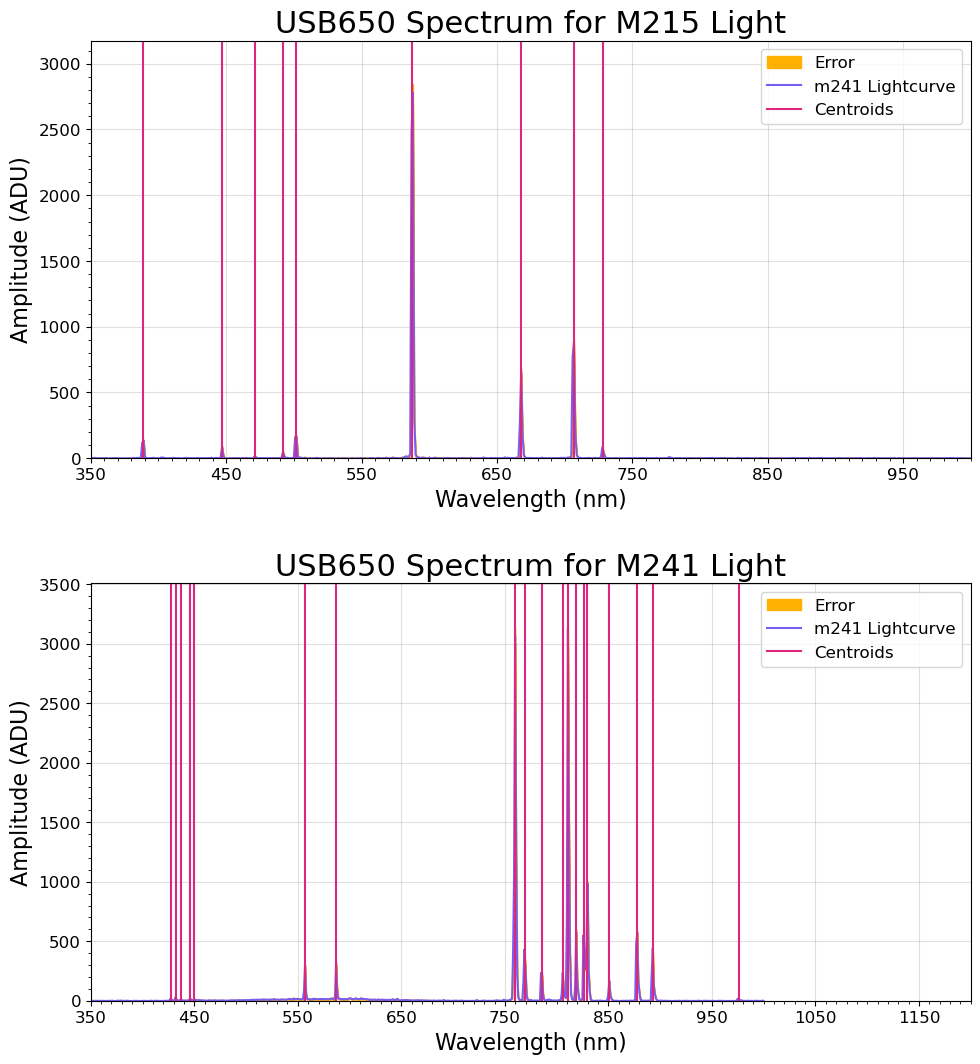

In [22]:
fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=2, wspace=0.3, hspace=0.3)

# Mystery 215

axs[0].set_ylim(0, np.max(brightness_array215)*1.1)
axs[0].set_xlim(350, 1000)

axs[0].set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 500))
axs[0].set_yticks(np.arange(0, np.max(brightness_array215)*1.1, 100), minor=True)

axs[0].set_xticks(np.arange(350, 1000, 100))
axs[0].set_xticks(np.arange(350, 1005, 10), minor=True)

axs[0].tick_params(labelsize=12)
axs[0].grid(visible=True, alpha=0.4)

axs[0].set_ylabel("Amplitude (ADU)", fontsize=16)
axs[0].set_xlabel("Wavelength (nm)", fontsize=16)
axs[0].set_title("USB650 Spectrum for " + data_dirs[1].capitalize() + " Light", fontsize=22)

axs[0].fill_between(wavelength_array, 
                mean_calibrated215 - 2*mean_calibrated_err215, 
                mean_calibrated215 + 2*mean_calibrated_err215, color='#FFB000', label="Error")
axs[0].plot(wavelength_array, mean_calibrated215, color='#785EF0', label=f"{selected_dir} Lightcurve")

for i in range(1, len(m215c)):
    axs[0].axvline(m215c[i], color="#DC267F")

axs[0].axvline(m215c[0], color="#DC267F", label="Centroids")
axs[0].legend(fontsize=12)

# Mystery 241

axs[1].set_ylim(0, np.max(brightness_array241)*1.1)
axs[1].set_xlim(350, 1000)

axs[1].set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 500))
axs[1].set_yticks(np.arange(0, np.max(brightness_array241)*1.1, 100), minor=True)

axs[1].set_xticks(np.arange(350, 1200, 100))
axs[1].set_xticks(np.arange(350, 1205, 10), minor=True)

axs[1].tick_params(labelsize=12)
axs[1].grid(visible=True, alpha=0.4)

axs[1].set_ylabel("Amplitude (ADU)", fontsize=16)
axs[1].set_xlabel("Wavelength (nm)", fontsize=16)
axs[1].set_title("USB650 Spectrum for " + data_dirs[2].capitalize() + " Light", fontsize=22)

axs[1].fill_between(wavelength_array, 
                mean_calibrated241 - 2*mean_calibrated_err241, 
                mean_calibrated241 + 2*mean_calibrated_err241, color='#FFB000', label="Error")
axs[1].plot(wavelength_array, mean_calibrated241, color='#785EF0', label=f"{selected_dir} Lightcurve")

for i in range(1, len(m241c)):
    axs[1].axvline(m241c[i], color="#DC267F")

axs[1].axvline(m241c[0], color="#DC267F", label="Centroids")
axs[1].legend(fontsize=12)

With that, let's check if our initial calibration using Hydrogen lines fits well for our new gases! Krypton will most likely be interesting since it shares even fewer wavelengths in the range of Hydrogen than Helium does. We'll compute the residuals of the largest peaks in both mysteries and Hydrogen (we now omit the 410.2nm peak entirely because of its proven discrepancy), except for special cases (such as the 760nm centroid for Kr I discussed above being between two peaks, or the Kr I 810nm peak which is surrounded by other sub-nm distance peaks). 

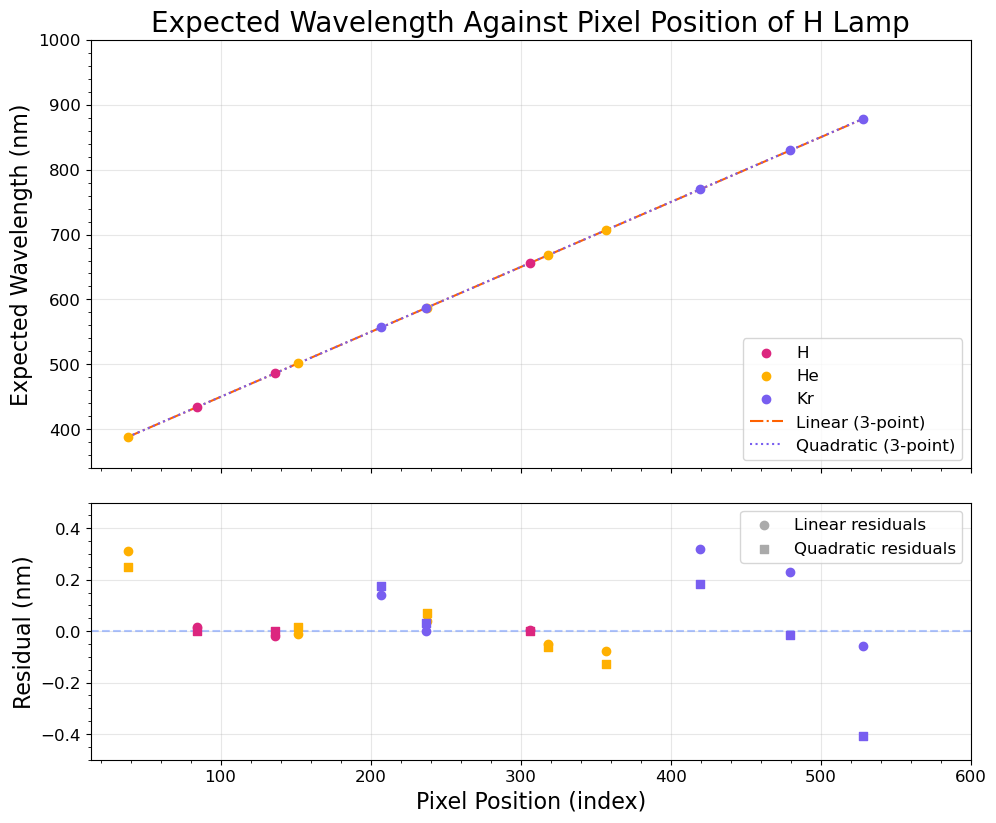

Absolute sum of residuals per fit:
Lin:	1.5752067401740533
Quad:	1.5084397409376038

Our fits are significantly worse now! Let's fitting to all these new points.


In [23]:
m215_centroids = [m215c[i] for i in [0, 4, 5, 6, 7]]
m215_centroids = np.array((m215_centroids - c1) / m1)
He_lines = np.array([388.8648, 501.56783, 587.5621, 667.8151, 706.5190])

m241_centroids = [m241c[i] for i in [5, 6, 8, 14, 16]]
m241_centroids = np.array((m241_centroids - c1) / m1)
Kr_lines = np.array([557.028944, 587.091599, 769.45401, 829.81099, 877.67505])

He_lin_res = lin_residuals(m215_centroids, He_lines, m1, c1)
He_quad_res = quad_residuals(m215_centroids, He_lines, quad_fit1[0], quad_fit1[1], quad_fit1[2])

Kr_lin_res = lin_residuals(m241_centroids, Kr_lines, m1, c1)
Kr_quad_res = quad_residuals(m241_centroids, Kr_lines, quad_fit1[0], quad_fit1[1], quad_fit1[2])

##########
# PLOTTING
##########

lin_range = np.arange(int(np.min(m215_centroids)), int(np.max(m241_centroids) + 1), 1)

fig, axs = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [5, 3], 'bottom': 0, 
                                                        'right': 1.5, 'top': 1.5, 'wspace': 0.3, 'hspace': 0.1})
plt.subplots_adjust(bottom=0, right=15, top=3, wspace=0.3, hspace=0.3)

##########
# DATA
##########

# gases
axs[0].scatter(peak_indices[1:], H_lines[1:], color="#DC267F", label="H", zorder=10)
axs[0].scatter(m215_centroids, He_lines, color="#FFB000", label="He", zorder=10)
axs[0].scatter(m241_centroids, Kr_lines, color="#785EF0", label="Kr", zorder=10)

# fits
axs[0].plot(lin_range, m1 * lin_range + c1, color="#FE6100", label="Linear (3-point)", ls="dashdot")
axs[0].plot(lin_range, quad_fit1[0] * lin_range**2 + quad_fit1[1] * lin_range + quad_fit1[2], 
            color="#785EF0", label="Quadratic (3-point)", ls="dotted")

axs[0].set_title("Expected Wavelength Against Pixel Position of H Lamp", fontsize=20)

axs[0].set_ylabel("Expected Wavelength (nm)", fontsize=16)

axs[0].set_yticks(np.arange(340, 1010, 20), minor=True)
axs[0].tick_params(labelsize=12)

axs[0].grid(visible=True, alpha=0.3)

##########
# RESIDUALS
##########
axs[1].scatter([], [], color="#AAAAAA", label="Linear residuals")
axs[1].scatter([], [], color="#AAAAAA", marker="s", label="Quadratic residuals")

axs[1].scatter(peak_indices[1:], lin_residuals1, color="#DC267F", zorder=10)
axs[1].scatter(peak_indices[1:], quad_residuals1, color="#DC267F", marker="s", zorder=10)

axs[1].scatter(m215_centroids, He_lin_res, color="#FFB000", zorder=10)
axs[1].scatter(m215_centroids, He_quad_res, color="#FFB000", marker="s", zorder=10)

axs[1].scatter(m241_centroids, Kr_lin_res, color="#785EF0", zorder=10)
axs[1].scatter(m241_centroids, Kr_quad_res, color="#785EF0", marker="s", zorder=10)

axs[1].set_yticks(np.arange(-0.5, 0.55, 0.05), minor=True)
axs[1].set_xticks(np.arange(20, 620, 20), minor=True)
axs[1].tick_params(labelsize=12)

axs[1].axhline(0, alpha=0.5, color="#648FFF", ls="dashed")

axs[1].set_xlabel("Pixel Position (index)", fontsize=16)
axs[1].set_ylabel("Residual (nm)", fontsize=16)

axs[1].grid(visible=True, alpha=0.3)

axs[0].legend(loc='lower right', fontsize=12)
axs[1].legend(fontsize=12)
plt.show()

print(f"Absolute sum of residuals per fit:\n" +
      f"Lin:\t{np.sum(np.abs(lin_residuals0)) + np.sum(np.abs(He_lin_res)) + np.sum(np.abs(Kr_lin_res))}\n" +
      f"Quad:\t{np.sum(np.abs(quad_residuals0)) + np.sum(np.abs(He_quad_res)) + np.sum(np.abs(Kr_quad_res))}\n"
     )

print(f"Our fits are significantly worse now! Let's fitting to all these new points.")

As expected, Helium and (particularly) Krypton do not align well with our fit from Hydrogen lines. Now however, we can recalibrate using our estimated location of the peaks in He I and Kr I in index. We can add these new points to the plot with Hydrogen points. We decide to omit the 410.2nm peak from Hydrogen from now onward since we now have many more peaks we can use!

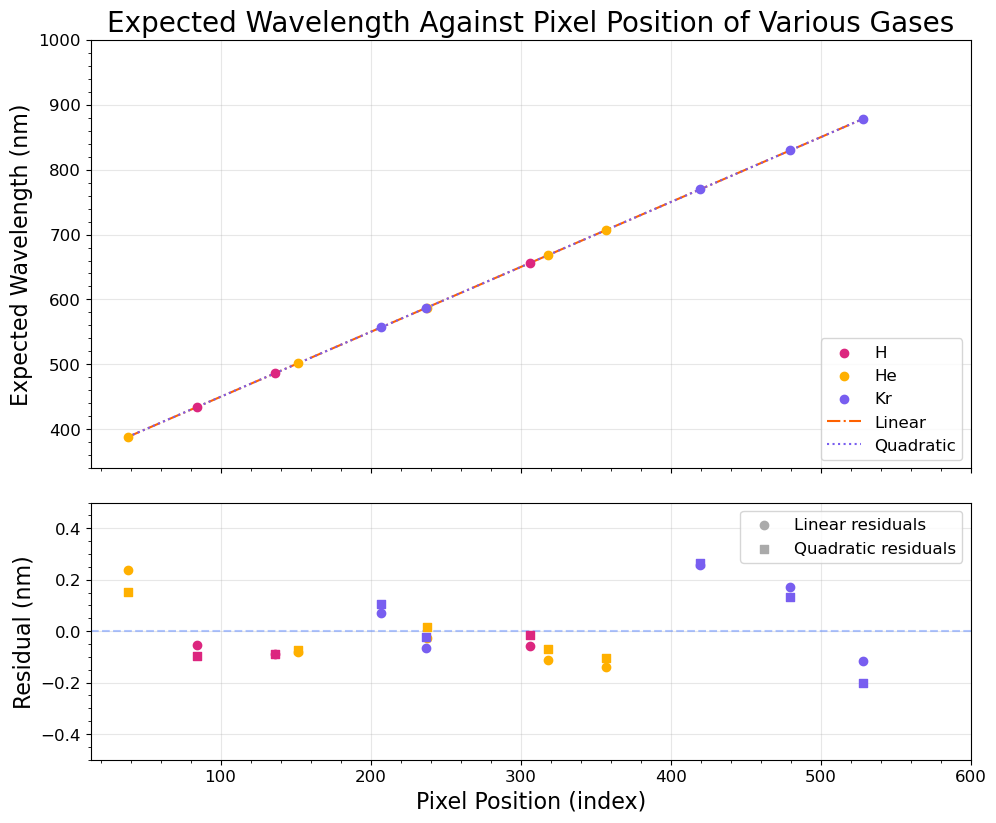

RMS of residuals per fit:
Lin:	0.1328137595189439
Quad:	0.12447144430604028



In [24]:
all_points = np.concatenate((peak_indices[1:], m215_centroids, m241_centroids))
all_known = np.concatenate((H_lines[1:], He_lines, Kr_lines))

new_m, new_c = least_squares(all_points, all_known, len(all_points))
new_lin_res = lin_residuals(all_points, all_known,new_m, new_c)

(new_quad_fit, new_quad_cov) = np.polyfit(all_points, all_known, 2, cov=True)
new_quad_res = quad_residuals(all_points, all_known, new_quad_fit[0], new_quad_fit[1], new_quad_fit[2])

##########
# PLOTTING
##########

lin_range = np.arange(int(np.min(m215_centroids)), int(np.max(m241_centroids) + 1), 1)

fig, axs = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [5, 3], 'bottom': 0, 
                                                        'right': 1.5, 'top': 1.5, 'wspace': 0.3, 'hspace': 0.1})
plt.subplots_adjust(bottom=0, right=15, top=3, wspace=0.3, hspace=0.3)

##########
# DATA
##########

# gases
axs[0].scatter(peak_indices[1:], H_lines[1:], color="#DC267F", label="H", zorder=10)
axs[0].scatter(m215_centroids, He_lines, color="#FFB000", label="He", zorder=10)
axs[0].scatter(m241_centroids, Kr_lines, color="#785EF0", label="Kr", zorder=10)

# fits
axs[0].plot(lin_range, new_m * lin_range + new_c, color="#FE6100", label="Linear", ls="dashdot")
axs[0].plot(lin_range, new_quad_fit[0] * lin_range**2 + new_quad_fit[1] * lin_range + new_quad_fit[2], 
            color="#785EF0", label="Quadratic", ls="dotted")

axs[0].set_title("Expected Wavelength Against Pixel Position of Various Gases", fontsize=20)

axs[0].set_ylabel("Expected Wavelength (nm)", fontsize=16)

axs[0].set_yticks(np.arange(340, 1010, 20), minor=True)
axs[0].tick_params(labelsize=12)

axs[0].grid(visible=True, alpha=0.3)

##########
# RESIDUALS
##########
axs[1].scatter([], [], color="#AAAAAA", label="Linear residuals")
axs[1].scatter([], [], color="#AAAAAA", marker="s", label="Quadratic residuals")

axs[1].scatter(peak_indices[1:], new_lin_res[:3], color="#DC267F", zorder=10)
axs[1].scatter(peak_indices[1:], new_quad_res[:3], color="#DC267F", marker="s", zorder=10)

axs[1].scatter(m215_centroids, new_lin_res[3:8], color="#FFB000", zorder=10)
axs[1].scatter(m215_centroids, new_quad_res[3:8], color="#FFB000", marker="s", zorder=10)

axs[1].scatter(m241_centroids, new_lin_res[8:], color="#785EF0", zorder=10)
axs[1].scatter(m241_centroids, new_quad_res[8:], color="#785EF0", marker="s", zorder=10)

axs[1].set_yticks(np.arange(-0.5, 0.55, 0.05), minor=True)
axs[1].set_xticks(np.arange(20, 620, 20), minor=True)
axs[1].tick_params(labelsize=12)

axs[1].axhline(0, alpha=0.5, color="#648FFF", ls="dashed")

axs[1].set_xlabel("Pixel Position (index)", fontsize=16)
axs[1].set_ylabel("Residual (nm)", fontsize=16)

axs[1].grid(visible=True, alpha=0.3)

axs[0].legend(loc='lower right', fontsize=12)
axs[1].legend(fontsize=12)
plt.show()

print(f"RMS of residuals per fit:\n" +
      f"Lin:\t{np.sqrt(np.sum(new_lin_res**2) / len(new_lin_res))}\n" +
      f"Quad:\t{np.sqrt(np.sum(new_quad_res**2) / len(new_quad_res))}\n"
     )

Maybe it could be useful to attempt higher order fits too! Let's have a look.

In [25]:
def cube_residuals(x_arr, y_arr, a, b, c, d):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using cubic regression of the form ax^3 + bx^2 + cx + d.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (a * (x_arr[i]**3) + b * (x_arr[i]**2) + c * x_arr[i] + d))
    
    return np.array(residuals)

def quint_residuals(x_arr, y_arr, a, b, c, d, e, f):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using 5th order regression.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (a * (x_arr[i]**5) + b * (x_arr[i]**4) + c * (x_arr[i]**3)
                                     + d * (x_arr[i]**2) + e * x_arr[i] + f))
    
    return np.array(residuals)

def tenth_residuals(x_arr, y_arr, fit):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using 10th order regression.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - (fit[0] * (x_arr[i]**10) + fit[1] * (x_arr[i]**9) + fit[2] * (x_arr[i]**8) 
                                     + fit[3] * (x_arr[i]**7) + fit[4] * (x_arr[i]**6) + fit[5] * (x_arr[i]**5) 
                                     + fit[6] * (x_arr[i]**4) + fit[7] * (x_arr[i]**3) + fit[8] * (x_arr[i]**2) 
                                     + fit[9] * x_arr[i] + fit[10]))
    
    return np.array(residuals)

(cube_fit, cube_cov) = np.polyfit(all_points, all_known, 3, cov=True)
cube_res = cube_residuals(all_points, all_known, cube_fit[0], cube_fit[1], cube_fit[2], cube_fit[3])

(quint_fit, quint_cov) = np.polyfit(all_points, all_known, 5, cov=True)
quint_res = quint_residuals(all_points, all_known, quint_fit[0], quint_fit[1], quint_fit[2], quint_fit[3], quint_fit[4], quint_fit[5])

(tenth_fit, tenth_cov) = np.polyfit(all_points, all_known, 10, cov=True)
tenth_res = tenth_residuals(all_points, all_known, tenth_fit)

We can plot their residuals too:

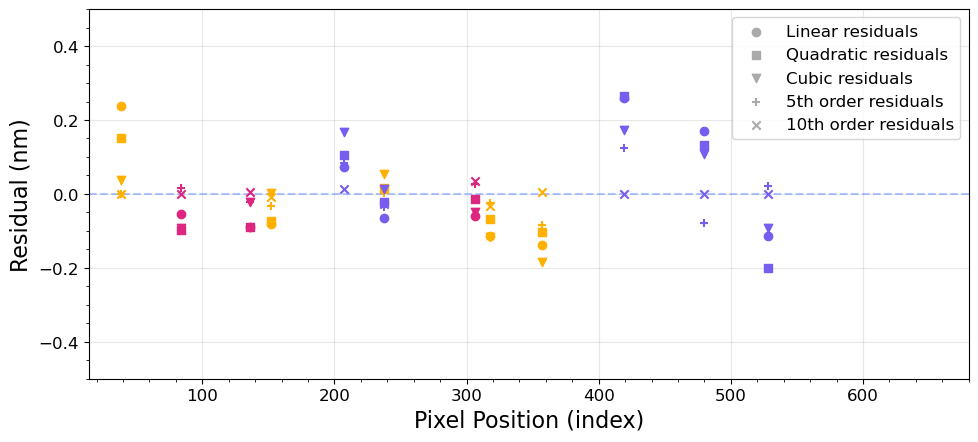

RMS of residuals per fit:
Lin:	0.1328137595189439
Quad:	0.12447144430604028
Cube:	0.10405689464073538
5th:	0.05621702177576491
10th:	0.016357628275055797



In [26]:
##########
# PLOTTING
##########

lin_range = np.arange(int(np.min(m215_centroids)), int(np.max(m241_centroids) + 1), 1)

fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(right=1.5)

##########
# RESIDUALS
##########
ax.scatter([], [], color="#AAAAAA", label="Linear residuals")
ax.scatter([], [], color="#AAAAAA", marker="s", label="Quadratic residuals")
ax.scatter([], [], color="#AAAAAA", marker="v", label="Cubic residuals")
ax.scatter([], [], color="#AAAAAA", marker="+", label="5th order residuals")
ax.scatter([], [], color="#AAAAAA", marker="x", label="10th order residuals")

ax.scatter(peak_indices[1:], new_lin_res[:3], color="#DC267F", zorder=10)
ax.scatter(peak_indices[1:], new_quad_res[:3], color="#DC267F", marker="s", zorder=10)
ax.scatter(peak_indices[1:], cube_res[:3], color="#DC267F", marker="v", zorder=10)
ax.scatter(peak_indices[1:], quint_res[:3], color="#DC267F", marker="+", zorder=10)
ax.scatter(peak_indices[1:], tenth_res[:3], color="#DC267F", marker="x", zorder=10)

ax.scatter(m215_centroids, new_lin_res[3:8], color="#FFB000", zorder=10)
ax.scatter(m215_centroids, new_quad_res[3:8], color="#FFB000", marker="s", zorder=10)
ax.scatter(m215_centroids, cube_res[3:8], color="#FFB000", marker="v", zorder=10)
ax.scatter(m215_centroids, quint_res[3:8], color="#FFB000", marker="+", zorder=10)
ax.scatter(m215_centroids, tenth_res[3:8], color="#FFB000", marker="x", zorder=10)

ax.scatter(m241_centroids, new_lin_res[8:], color="#785EF0", zorder=10)
ax.scatter(m241_centroids, new_quad_res[8:], color="#785EF0", marker="s", zorder=10)
ax.scatter(m241_centroids, cube_res[8:], color="#785EF0", marker="v", zorder=10)
ax.scatter(m241_centroids, quint_res[8:], color="#785EF0", marker="+", zorder=10)
ax.scatter(m241_centroids, tenth_res[8:], color="#785EF0", marker="x", zorder=10)

ax.set_yticks(np.arange(-0.5, 0.55, 0.05), minor=True)
ax.set_xticks(np.arange(20, 700, 20), minor=True)
ax.tick_params(labelsize=12)

ax.axhline(0, alpha=0.5, color="#648FFF", ls="dashed")

ax.set_xlabel("Pixel Position (index)", fontsize=16)
ax.set_ylabel("Residual (nm)", fontsize=16)

ax.grid(visible=True, alpha=0.3)

ax.legend( fontsize=12)
ax.legend(fontsize=12)
plt.show()

print(f"RMS of residuals per fit:\n" +
      f"Lin:\t{np.sqrt(np.sum(new_lin_res**2) / len(new_lin_res))}\n" +
      f"Quad:\t{np.sqrt(np.sum(new_quad_res**2) / len(new_quad_res))}\n" + 
      f"Cube:\t{np.sqrt(np.sum(cube_res**2) / len(cube_res))}\n" + 
      f"5th:\t{np.sqrt(np.sum(quint_res**2) / len(quint_res))}\n" + 
      f"10th:\t{np.sqrt(np.sum(tenth_res**2) / len(tenth_res))}\n"
     )

Overall, we get significantly lower residuals with a larger order polynomial, which is to be expected. We stop here at the 10th order, but we have 13 points so any polynomial up to the 11th order will give non-zero residuals!